# Лабораторная работа №12. Transfer Learning, PCA и SVD признаков

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №12».

**Данные.** Hymenoptera — учебный набор из руководства PyTorch по transfer learning: фотографии муравьёв и пчёл, 2 класса, 245 картинок для обучения и 153 для проверки. Архив (≈ 45 МБ) скачивается при первом запуске в `data/datasets/` (в git не хранится). Сеть — ResNet18 с весами, обученными на ImageNet (≈ 45 МБ, скачивается `torchvision`).

## 1. О чём эта работа

### Знакомый пример

Человек, который умеет играть на гитаре, осваивает укулеле за пару вечеров: слух, координация пальцев, чувство ритма уже есть, нужно лишь привыкнуть к новому инструменту. Учиться с нуля было бы намного дольше.

### Основная идея

Нейросеть, обученная различать 1000 классов на миллионе фотографий, уже «умеет видеть»: её слои находят границы, текстуры, шерсть, глаза, крылья. Эти умения полезны и для новой задачи — скажем, отличать муравьёв от пчёл по паре сотен фотографий. **Transfer learning**: берём готовую сеть, отрезаем последний слой (он отвечал за старые 1000 классов), ставим новый — на 2 класса — и обучаем только его. Если данных хватает, можно слегка дообучить и последние слои самой сети — **fine-tuning**.

Вторая часть работы — заглянуть внутрь. Перед последним слоем сеть превращает картинку в вектор из 512 чисел — **embedding**. Картинки одного класса должны давать похожие векторы. Проверим это математически.

### Понятия

- **Backbone** — основная часть сети, превращающая картинку в embedding. **Head** — последний слой, превращающий embedding в ответы по классам.
- **Frozen backbone** — веса backbone не меняются, обучается только head.
- **Cosine similarity** — косинус угла между двумя векторами: 1 — смотрят в одну сторону, 0 — перпендикулярны, −1 — в противоположные. Длины векторов не учитываются, только направление.
- **Центрирование** — вычитание среднего вектора из всех данных; облако точек сдвигается так, чтобы его центр оказался в нуле.
- **PCA** (метод главных компонент) — способ найти направления, вдоль которых данные разбросаны сильнее всего. Первая главная компонента — направление наибольшего разброса; вторая — наибольшего из перпендикулярных первой, и так далее. Проекция на первые две компоненты — лучшая (по сохранённому разбросу) плоская «фотография» многомерного облака.
- **Собственные векторы ковариационной матрицы** (лабораторные 1 и 5) — это и есть главные компоненты; собственные значения — дисперсии вдоль них.
- **SVD** (сингулярное разложение, встречалось в лабораторных 3 и 6): $X=U\Sigma V^T$. Строки $V^T$ — те же главные компоненты, а сингулярные числа $\sigma_i$ связаны с дисперсиями: $\lambda_i=\sigma_i^2/N$.
- **Rank-k approximation** — приближение матрицы, в котором оставлены только $k$ наибольших сингулярных чисел. **Explained energy** — какая доля суммарного квадрата элементов при этом сохранена.
- **Macro-F1** — среднее по классам от F1 (F1 — гармоническое среднее precision и recall, лабораторная 10). В отличие от accuracy, даёт каждому классу равный вес независимо от его размера.

### Формулы

$$\cos(x,y)=\frac{x^Ty}{\|x\|\cdot\|y\|}$$

$$X_c=X-\mu,\qquad C=\frac1NX_c^TX_c$$

$$X=U\Sigma V^T,\qquad \text{explained energy}_k=\frac{\sum_{i\le k}\sigma_i^2}{\sum_i\sigma_i^2}$$

In [1]:
import copy, glob, os, time, urllib.request, zipfile
import numpy as np
import torch
import torch.nn as nn
import torchvision
from PIL import Image
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80})

SEED = 0
DATA_URL = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
DATA_ROOT = "data/datasets"
HEAD_EPOCHS, HEAD_LR = 200, 1e-2
FT_EPOCHS, FT_LR_BACKBONE, FT_LR_HEAD, FT_BATCH = 5, 1e-5, 1e-4, 32
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED); np.random.seed(SEED)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

torch 2.14.1+cpu | torchvision 0.29.1+cpu | device: cpu


## 2. Вопрос 1 — cosine similarity

> Для x=[1,2,2], y=[2,1,2] найдите cosine similarity.

**Скалярное произведение:** $x^Ty=1\cdot2+2\cdot1+2\cdot2=2+2+4=8$.

**Длины:** $\|x\|=\sqrt{1+4+4}=3$, $\|y\|=\sqrt{4+1+4}=3$.

$$\cos(x,y)=\frac{8}{3\cdot3}=\frac89\approx0.8889$$

**Смысл.** Угол между векторами $\arccos(0.8889)\approx27.3°$ — они смотрят почти в одну сторону. Если умножить $x$ на 10, числитель и $\|x\|$ вырастут в 10 раз и сократятся: косинус не изменится. Для embedding это полезно: «яркая» картинка может дать вектор большей длины, но с тем же направлением.

In [2]:
x = np.array([1.0, 2, 2]); y = np.array([2.0, 1, 2])
cos = x @ y / (np.linalg.norm(x) * np.linalg.norm(y))
print(f"x·y = {x @ y}, ||x|| = {np.linalg.norm(x)}, ||y|| = {np.linalg.norm(y)}, cos = {cos:.4f}, угол = {np.degrees(np.arccos(cos)):.2f}°")
print("cos(10x, y) =", round((10 * x) @ y / (np.linalg.norm(10 * x) * np.linalg.norm(y)), 4), "— масштаб не влияет")
print("евклидово расстояние: ||x−y|| =", round(np.linalg.norm(x - y), 4), ", ||10x−y|| =", round(np.linalg.norm(10 * x - y), 4), "— а оно зависит от масштаба")

x·y = 8.0, ||x|| = 3.0, ||y|| = 3.0, cos = 0.8889, угол = 27.27°
cos(10x, y) = 0.8889 — масштаб не влияет
евклидово расстояние: ||x−y|| = 1.4142 , ||10x−y|| = 27.3679 — а оно зависит от масштаба


**Итог вопроса 1:** $\cos=8/9\approx0.8889$.

## 3. Вопрос 2 — PCA вручную и энергия SVD

> Для точек (1,1),(2,2),(3,3) найдите PCA вручную. Затем для singular values [10,3,1] найдите долю энергии rank-1 и rank-2 approximation.

### PCA

**Шаг 1. Среднее:** $\mu=\big(\tfrac{1+2+3}{3},\tfrac{1+2+3}{3}\big)=(2,2)$.

**Шаг 2. Центрирование:** $(-1,-1),\ (0,0),\ (1,1)$.

**Шаг 3. Ковариационная матрица.** $C=\frac1NX_c^TX_c$. Сумма квадратов первой координаты: $1+0+1=2$; второй — тоже 2; сумма произведений: $(-1)(-1)+0+1\cdot1=2$.

$$C=\frac13\begin{bmatrix}2&2\\2&2\end{bmatrix}=\begin{bmatrix}2/3&2/3\\2/3&2/3\end{bmatrix}$$

**Шаг 4. Собственные значения:** $\det(C-\lambda I)=(\tfrac23-\lambda)^2-\tfrac49=\lambda^2-\tfrac43\lambda=\lambda(\lambda-\tfrac43)=0$, откуда $\lambda_1=\tfrac43$, $\lambda_2=0$.

**Шаг 5. Собственные векторы.** Для $\lambda_1=\tfrac43$: $(\tfrac23-\tfrac43)v_x+\tfrac23v_y=0\Rightarrow v_x=v_y$, после нормировки $\text{PC}_1=(1,1)/\sqrt2$. Для $\lambda_2=0$: $\text{PC}_2=(1,-1)/\sqrt2$.

**Смысл.** Все три точки лежат на прямой $y=x$. Первая компонента направлена вдоль неё и объясняет 100 % разброса; вдоль второй разброса нет ($\lambda_2=0$). Данные формально двумерные, но по сути одномерные: вместо двух координат достаточно одной — положения на прямой: $-\sqrt2,\ 0,\ \sqrt2$.

### Энергия SVD

Сингулярные числа $[10,3,1]$. Энергия — сумма квадратов: $100+9+1=110$.

- rank-1 (оставляем только $\sigma_1$): $100/110\approx90.91\%$;
- rank-2: $(100+9)/110=109/110\approx99.09\%$.

**Смысл.** Одно направление несёт 91 % всей «массы» матрицы, два — 99 %. Третье можно отбросить почти без потерь. Обратите внимание: считаются **квадраты**. По самим числам первое составляет $10/14=71\%$, но энергия — это дисперсия, а дисперсия квадратична.

In [3]:
P = np.array([[1.0, 1], [2, 2], [3, 3]])
mu = P.mean(axis=0); Pc = P - mu
C = Pc.T @ Pc / len(P)
vals, vecs = np.linalg.eigh(C)
print("mean:", mu, "\ncentered:\n", Pc, "\nC =\n", C)
print("eigenvalues:", vals[::-1], " PC1 =", vecs[:, -1] * np.sign(vecs[0, -1]), " (1,1)/√2 =", np.ones(2) / np.sqrt(2))

U, S, Vt = np.linalg.svd(Pc, full_matrices=False)
print("через SVD: σ =", S, " σ²/N =", S ** 2 / len(P), " V[0] =", Vt[0] * np.sign(Vt[0, 0]))
print("проекции на PC1:", Pc @ (np.ones(2) / np.sqrt(2)))

sv = np.array([10.0, 3, 1])
energy = np.cumsum(sv ** 2) / np.sum(sv ** 2)
print(f"\nэнергия: всего {np.sum(sv ** 2)}, rank-1 = {100 * energy[0]:.2f} %, rank-2 = {100 * energy[1]:.2f} %")

# проверка на настоящей матрице с такими сингулярными числами: ошибка rank-k приближения
rng = np.random.default_rng(0)
Q1, _ = np.linalg.qr(rng.normal(size=(5, 3))); Q2, _ = np.linalg.qr(rng.normal(size=(3, 3)))
A = Q1 @ np.diag(sv) @ Q2.T
for k in (1, 2):
    Uk, Sk, Vk = np.linalg.svd(A, full_matrices=False)
    Ak = Uk[:, :k] @ np.diag(Sk[:k]) @ Vk[:k]
    print(f"  rank-{k}: 1 − ||A − A_k||²_F / ||A||²_F = {1 - np.linalg.norm(A - Ak) ** 2 / np.linalg.norm(A) ** 2:.4f}")

mean: [2. 2.] 
centered:
 [[-1. -1.]
 [ 0.  0.]
 [ 1.  1.]] 
C =
 [[0.6667 0.6667]
 [0.6667 0.6667]]
eigenvalues: [1.3333 0.    ]  PC1 = [0.7071 0.7071]  (1,1)/√2 = [0.7071 0.7071]
через SVD: σ = [2. 0.]  σ²/N = [1.3333 0.    ]  V[0] = [0.7071 0.7071]
проекции на PC1: [-1.4142  0.      1.4142]

энергия: всего 110.0, rank-1 = 90.91 %, rank-2 = 99.09 %
  rank-1: 1 − ||A − A_k||²_F / ||A||²_F = 0.9091
  rank-2: 1 − ||A − A_k||²_F / ||A||²_F = 0.9909


**Итог вопроса 2:** $\text{PC}_1=(1,1)/\sqrt2$, $\lambda=(4/3,\ 0)$; энергия 90.91 % и 99.09 %.

Проверка показала связь двух способов: собственные значения ковариационной матрицы равны $\sigma^2/N$, а главные компоненты — строки $V^T$ из SVD центрированных данных. Доля энергии rank-$k$ приближения — это буквально «какую часть квадрата нормы Фробениуса матрицы оно воспроизводит».

## 4. Задание 3 — код и эксперимент

### Шаг 1. Датасет

Картинки приводятся к виду, на котором обучалась ResNet18: размер 224×224, вычитание средних и деление на стандартные отклонения каналов ImageNet.

train: (245, 3, 224, 224) по классам: [124, 121]
val  : (153, 3, 224, 224) по классам: [70, 83]


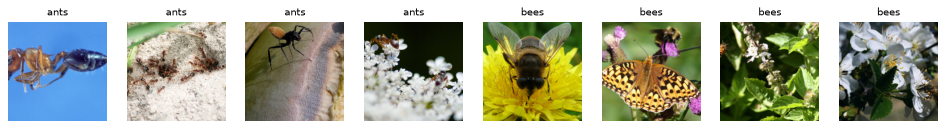

In [4]:
root = os.path.join(DATA_ROOT, "hymenoptera_data")
if not os.path.isdir(root):
    os.makedirs(DATA_ROOT, exist_ok=True)
    zpath = os.path.join(DATA_ROOT, "hymenoptera_data.zip")
    urllib.request.urlretrieve(DATA_URL, zpath)
    with zipfile.ZipFile(zpath) as z: z.extractall(DATA_ROOT)
    os.remove(zpath)

CLASSES = ["ants", "bees"]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf = torchvision.transforms.Compose([
    torchvision.transforms.Resize(256), torchvision.transforms.CenterCrop(224),
    torchvision.transforms.ToTensor(), torchvision.transforms.Normalize(MEAN, STD)])

def load_split(split):
    xs, ys = [], []
    for k, cls in enumerate(CLASSES):
        for f in sorted(glob.glob(os.path.join(root, split, cls, "*"))):
            try:
                xs.append(tf(Image.open(f).convert("RGB"))); ys.append(k)
            except Exception:
                pass                                   # в наборе есть один битый файл
    return torch.stack(xs), torch.tensor(ys)

Xtr, ytr = load_split("train"); Xva, yva = load_split("val")
print("train:", tuple(Xtr.shape), "по классам:", torch.bincount(ytr).tolist())
print("val  :", tuple(Xva.shape), "по классам:", torch.bincount(yva).tolist())

def show(img):
    return (img.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)

fig, ax = plt.subplots(1, 8, figsize=(15, 2.2))
for a_, i in zip(ax, [0, 1, 2, 3, len(Xtr) - 1, len(Xtr) - 2, len(Xtr) - 3, len(Xtr) - 4]):
    a_.imshow(show(Xtr[i])); a_.set_title(CLASSES[ytr[i]], fontsize=9); a_.axis("off")
plt.show()

### Шаги 2–3. Pretrained ResNet18, замена classifier, заморозка backbone

ResNet18 устроена так: начальная свёртка → четыре «стадии» (`layer1`…`layer4`) → усреднение по пространству (`avgpool`) → вектор из 512 чисел → полносвязный слой `fc` на 1000 классов. Мы заменяем `fc` на слой с двумя выходами.

**Приём для скорости.** Пока часть сети заморожена, её выход для данной картинки всегда один и тот же. Поэтому его можно вычислить один раз и сохранить. Мы считаем и храним выход `layer3` (карта 256×14×14). Тогда:

- embedding = `avgpool(layer4(·))` от сохранённого;
- обучение head при замороженном backbone — это обучение линейного слоя на готовых embeddings;
- fine-tuning `layer4` — обучение `layer4` + head на сохранённых выходах `layer3`.

Результат математически тот же, что при прогоне всей сети на каждом шаге, но в десятки раз быстрее. Цена — нельзя использовать аугментацию (случайные отражения и обрезки), потому что входы зафиксированы.

In [5]:
def make_backbone(pretrained):
    torch.manual_seed(SEED)
    w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    return torchvision.models.resnet18(weights=w, progress=False).eval()

@torch.no_grad()
def stem_features(m, X, bs=32):
    """Выход layer3 для всех картинок: эта часть сети заморожена во всех экспериментах."""
    out = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs]
        x = m.maxpool(m.relu(m.bn1(m.conv1(x))))
        out.append(m.layer3(m.layer2(m.layer1(x))))
    return torch.cat(out)

@torch.no_grad()
def embed(layer4, F3, bs=64):
    """Embedding до classifier: layer4 → global average pooling → вектор 512."""
    layer4.eval()
    return torch.cat([layer4(F3[i:i + bs]).mean(dim=(2, 3)) for i in range(0, len(F3), bs)])

resnet = make_backbone(pretrained=True)
n_backbone = sum(p.numel() for n, p in resnet.named_parameters() if not n.startswith("fc."))
n_layer4 = sum(p.numel() for p in resnet.layer4.parameters())
print(f"параметров в backbone: {n_backbone:,}; из них в layer4: {n_layer4:,}; в старом fc (512→1000): {sum(p.numel() for p in resnet.fc.parameters()):,}")

t0 = time.perf_counter()
F3_tr, F3_va = stem_features(resnet, Xtr), stem_features(resnet, Xva)
E_tr, E_va = embed(resnet.layer4, F3_tr), embed(resnet.layer4, F3_va)
print(f"выход layer3: {tuple(F3_tr.shape)}; embeddings: train {tuple(E_tr.shape)}, val {tuple(E_va.shape)}; время {time.perf_counter() - t0:.1f} с")

параметров в backbone: 11,176,512; из них в layer4: 8,393,728; в старом fc (512→1000): 513,000


выход layer3: (245, 256, 14, 14); embeddings: train (245, 512), val (153, 512); время 5.7 с


### Шаг 4. Обучение только head; accuracy и macro-F1

Новый слой `Linear(512 → 2)` — это $512\cdot2+2=1026$ обучаемых чисел. Метрики считаем собственной функцией.

In [6]:
def classification_metrics(pred, target, n_classes=2):
    pred, target = np.asarray(pred), np.asarray(target)
    f1s = []
    for k in range(n_classes):
        tp = np.sum((pred == k) & (target == k)); fp = np.sum((pred == k) & (target != k)); fn = np.sum((pred != k) & (target == k))
        prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * prec * rec / (prec + rec) if prec + rec else 0.0)
    return float((pred == target).mean()), float(np.mean(f1s))

def train_head(E_train, y_train, epochs=HEAD_EPOCHS, lr=HEAD_LR):
    torch.manual_seed(SEED)
    head = nn.Linear(E_train.shape[1], 2)
    opt = torch.optim.Adam(head.parameters(), lr=lr, weight_decay=1e-3)
    for _ in range(epochs):
        loss = nn.functional.cross_entropy(head(E_train), y_train)
        opt.zero_grad(); loss.backward(); opt.step()
    return head, loss.item()

head_frozen, loss_frozen = train_head(E_tr, ytr)
with torch.no_grad():
    pred_frozen = head_frozen(E_va).argmax(1)
acc_frozen, f1_frozen = classification_metrics(pred_frozen, yva)
print(f"обучаемых параметров: {sum(p.numel() for p in head_frozen.parameters())}")
print(f"frozen backbone: train loss {loss_frozen:.4f}, val accuracy {acc_frozen:.4f}, macro-F1 {f1_frozen:.4f}")

обучаемых параметров: 1026
frozen backbone: train loss 0.0051, val accuracy 0.9608, macro-F1 0.9606


### Шаги 5–7. Embeddings, центрирование, PCA, 2D scatter

PCA реализована через SVD центрированной матрицы (собственной функцией, без sklearn). Математическая схема:

1. $X$ — матрица embeddings, строка — картинка, 512 столбцов.
2. $X_c=X-\mu$ — вычитаем средний embedding.
3. $X_c=U\Sigma V^T$.
4. Главные компоненты — строки $V^T$; доля дисперсии компоненты $i$ равна $\sigma_i^2/\sum\sigma^2$.
5. Координаты картинок в новых осях: $X_cV$; берём первые два столбца.

Для проверки то же считается вторым способом — через собственные значения ковариационной матрицы.

In [7]:
def pca(E, k=2):
    X = np.asarray(E, dtype=np.float64)
    mu = X.mean(axis=0)
    Xc = X - mu
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    explained = S ** 2 / np.sum(S ** 2)
    return Xc @ Vt[:k].T, explained, Vt, mu, S

Z_frozen, expl_frozen, Vt_f, mu_f, S_f = pca(E_va.numpy())
Xc = E_va.numpy().astype(np.float64) - mu_f
eig = np.sort(np.linalg.eigvalsh(Xc.T @ Xc / len(Xc)))[::-1]
print("проверка: собственные значения ковариации == σ²/N:", np.allclose(eig[:10], (S_f ** 2 / len(Xc))[:10]))
print(f"доля дисперсии: PC1 = {100 * expl_frozen[0]:.1f} %, PC2 = {100 * expl_frozen[1]:.1f} %, вместе {100 * expl_frozen[:2].sum():.1f} %")
cum = np.cumsum(expl_frozen)
for thr in (0.5, 0.9, 0.95, 0.99):
    print(f"  {int(thr * 100)} % дисперсии дают первые {int(np.searchsorted(cum, thr) + 1)} компонент из {len(cum)}")

проверка: собственные значения ковариации == σ²/N:

 True
доля дисперсии: PC1 = 12.7 %, PC2 = 7.2 %, вместе 19.9 %
  50 % дисперсии дают первые 14 компонент из 153
  90 % дисперсии дают первые 72 компонент из 153
  95 % дисперсии дают первые 95 компонент из 153
  99 % дисперсии дают первые 131 компонент из 153


### Шаг 8. Cosine similarity: пары одного класса и разных классов

Матрица попарных косинусов считается одним матричным умножением: если каждую строку поделить на её длину, то $EE^T$ — таблица всех косинусов. Диагональ (картинка сама с собой, косинус 1) исключается.

Считаем двумя способами: на исходных embeddings и на центрированных (после вычитания среднего embedding).

In [8]:
def cosine_same_diff(E, labels, center=None):
    E = np.asarray(E, dtype=np.float64)
    if center is not None: E = E - center
    E = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12)
    S = E @ E.T
    labels = np.asarray(labels)
    same = labels[:, None] == labels[None, :]
    off_diag = ~np.eye(len(labels), dtype=bool)
    return S[same & off_diag].mean(), S[~same].mean()

s_raw, d_raw = cosine_same_diff(E_va, yva)
mu_train = E_tr.numpy().mean(axis=0)
s_c, d_c = cosine_same_diff(E_va, yva, center=mu_train)
print(f"исходные embeddings      : same-class {s_raw:.3f}, different-class {d_raw:.3f}, разность {s_raw - d_raw:.3f}")
print(f"центрированные embeddings: same-class {s_c:.3f}, different-class {d_c:.3f}, разность {s_c - d_c:.3f}")
print("минимальный элемент embedding:", float(E_va.min()), "— после ReLU и усреднения все компоненты неотрицательны")

исходные embeddings      : same-class 0.667, different-class 0.597, разность 0.070
центрированные embeddings: same-class 0.095, different-class -0.086, разность 0.181
минимальный элемент embedding: 0.0 — после ReLU и усреднения все компоненты неотрицательны


### Шаги 9–10. Fine-tuning последней стадии

Размораживаем `layer4` и дообучаем его вместе с head. Скорость обучения для `layer4` — 1e-5, в 10 раз меньше, чем для head, и в 1000 раз меньше, чем была при обучении head: веса backbone уже хорошие, и большие шаги могут их испортить. Head стартует с уже обученных весов.

Значение подобрано не с первой попытки. При 1e-4 loss на train в первой же эпохе подскочил с 0.005 до 0.39 — шаг оказался разрушительным для готовых весов, и accuracy на val упала с 0.961 до 0.948. Решение уменьшить шаг принято по поведению loss на **train**, а не по метрике на val.

Слои BatchNorm внутри `layer4` оставлены в режиме `eval` (их накопленная статистика не пересчитывается): на 245 картинках пересчёт статистики по маленьким batch'ам был бы шумным.

In [9]:
torch.manual_seed(SEED)
layer4_ft = copy.deepcopy(resnet.layer4)
head_ft = copy.deepcopy(head_frozen)
for p_ in layer4_ft.parameters(): p_.requires_grad_(True)
opt = torch.optim.Adam([{"params": layer4_ft.parameters(), "lr": FT_LR_BACKBONE}, {"params": head_ft.parameters(), "lr": FT_LR_HEAD}])
n_trainable_ft = sum(p.numel() for p in layer4_ft.parameters()) + sum(p.numel() for p in head_ft.parameters())

def eval_ft():
    with torch.no_grad():
        Ev = embed(layer4_ft, F3_va); pr = head_ft(Ev).argmax(1)
    return classification_metrics(pr, yva), Ev, pr

g = torch.Generator().manual_seed(SEED)
t0 = time.perf_counter()
print(f"до fine-tuning: val acc/F1 = {eval_ft()[0]}")
for epoch in range(1, FT_EPOCHS + 1):
    layer4_ft.eval()                                    # BatchNorm со старой статистикой; градиенты всё равно считаются
    perm = torch.randperm(len(F3_tr), generator=g); tot = 0.0
    for i in range(0, len(perm), FT_BATCH):
        idx = perm[i:i + FT_BATCH]
        loss = nn.functional.cross_entropy(head_ft(layer4_ft(F3_tr[idx]).mean(dim=(2, 3))), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
    (acc, f1), _, _ = eval_ft()
    print(f"epoch {epoch}: train loss {tot / len(perm):.4f} | val accuracy {acc:.4f}, macro-F1 {f1:.4f}")
print(f"обучаемых параметров: {n_trainable_ft:,}; время {time.perf_counter() - t0:.1f} с")

(acc_ft, f1_ft), E_va_ft, pred_ft = eval_ft()
E_tr_ft = embed(layer4_ft, F3_tr)
Z_ft, expl_ft, _, _, _ = pca(E_va_ft.numpy())
s_raw_ft, d_raw_ft = cosine_same_diff(E_va_ft, yva)
s_c_ft, d_c_ft = cosine_same_diff(E_va_ft, yva, center=E_tr_ft.numpy().mean(axis=0))

до fine-tuning: val acc/F1 = (0.9607843137254902, 0.9605805565097905)


epoch 1: train loss 0.0086 | val accuracy 0.9608, macro-F1 0.9606


epoch 2: train loss 0.0033 | val accuracy 0.9673, macro-F1 0.9671


epoch 3: train loss 0.0011 | val accuracy 0.9608, macro-F1 0.9606


epoch 4: train loss 0.0011 | val accuracy 0.9608, macro-F1 0.9606


epoch 5: train loss 0.0005 | val accuracy 0.9673, macro-F1 0.9671
обучаемых параметров: 8,394,754; время 10.1 с


### Контрольный опыт: backbone без pretrain

Чтобы увидеть, что именно дал перенос, повторим «frozen»-эксперимент с той же архитектурой, но со случайными весами: head обучается на embeddings необученной сети.

In [10]:
rand_net = make_backbone(pretrained=False)
E_tr_r = embed(rand_net.layer4, stem_features(rand_net, Xtr)); E_va_r = embed(rand_net.layer4, stem_features(rand_net, Xva))
# масштаб признаков у необученной сети другой — стандартизуем по train, чтобы обучение head было честным
m_r, s_r = E_tr_r.mean(0), E_tr_r.std(0) + 1e-6
head_r, _ = train_head((E_tr_r - m_r) / s_r, ytr)
with torch.no_grad():
    pred_r = head_r((E_va_r - m_r) / s_r).argmax(1)
acc_r, f1_r = classification_metrics(pred_r, yva)
Z_r, expl_r, _, _, _ = pca(E_va_r.numpy())
s_c_r, d_c_r = cosine_same_diff(E_va_r, yva, center=E_tr_r.numpy().mean(axis=0))
s_raw_r, d_raw_r = cosine_same_diff(E_va_r, yva)

### Шаг 11. Сравнение: таблица и геометрия признаков

Кроме косинусов, считаем ещё один показатель разделимости — **точность классификатора «ближайший центр класса»**: для каждого класса берём средний embedding по train, картинку из val относим к ближайшему центру. Считаем это в полном 512-мерном пространстве и в двумерной PCA-проекции — чтобы понять, сколько информации о классах теряет картинка.

Режим                      Trainable params  Accuracy  Macro-F1   Same/Diff cos   Same/Diff cos (центр.)
random backbone + head                1,026    0.6078    0.6078   0.989 / 0.989          +0.037 / -0.035
frozen backbone + head                1,026    0.9608    0.9606   0.667 / 0.597          +0.095 / -0.086
fine-tuned layer4 + head          8,394,754    0.9673    0.9671   0.675 / 0.601          +0.103 / -0.093

Режим                       ближайший центр, 512-D  ближайший центр, PCA 2-D   дисперсия в PC1+PC2
random backbone + head                      0.6275                    0.6275                 89.7%
frozen backbone + head                      0.9608                    0.9346                 19.9%
fine-tuned layer4 + head                    0.9608                    0.9608                 20.8%


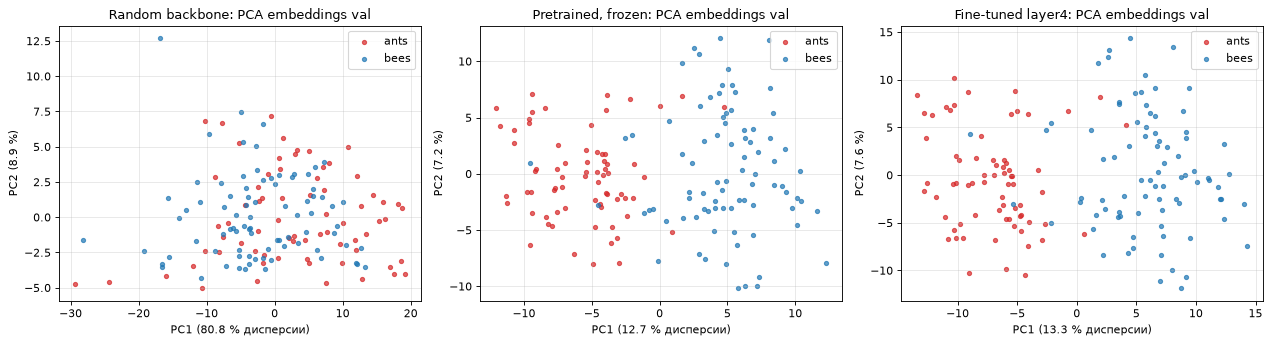

In [11]:
def nearest_centroid_acc(Etr, ytr_, Eva, yva_):
    Etr, Eva = np.asarray(Etr, np.float64), np.asarray(Eva, np.float64)
    cents = np.stack([Etr[np.asarray(ytr_) == k].mean(axis=0) for k in range(2)])
    pred = ((Eva[:, None, :] - cents[None]) ** 2).sum(2).argmin(1)
    return float((pred == np.asarray(yva_)).mean())

def nc_in_pca2(Etr, ytr_, Eva, yva_):
    _, _, Vt, mu, _ = pca(np.asarray(Etr))
    proj = lambda E: (np.asarray(E, np.float64) - mu) @ Vt[:2].T
    return nearest_centroid_acc(proj(Etr), ytr_, proj(Eva), yva_)

rows = [
    ("random backbone + head", 1026, acc_r, f1_r, s_raw_r, d_raw_r, s_c_r, d_c_r, nearest_centroid_acc(E_tr_r, ytr, E_va_r, yva), nc_in_pca2(E_tr_r, ytr, E_va_r, yva), expl_r),
    ("frozen backbone + head", 1026, acc_frozen, f1_frozen, s_raw, d_raw, s_c, d_c, nearest_centroid_acc(E_tr, ytr, E_va, yva), nc_in_pca2(E_tr, ytr, E_va, yva), expl_frozen),
    ("fine-tuned layer4 + head", n_trainable_ft, acc_ft, f1_ft, s_raw_ft, d_raw_ft, s_c_ft, d_c_ft, nearest_centroid_acc(E_tr_ft, ytr, E_va_ft, yva), nc_in_pca2(E_tr_ft, ytr, E_va_ft, yva), expl_ft),
]
print(f"{'Режим':26}{'Trainable params':>17}{'Accuracy':>10}{'Macro-F1':>10}{'Same/Diff cos':>16}{'Same/Diff cos (центр.)':>25}")
for r in rows:
    print(f"{r[0]:26}{r[1]:17,}{r[2]:10.4f}{r[3]:10.4f}{f'{r[4]:.3f} / {r[5]:.3f}':>16}{f'{r[6]:+.3f} / {r[7]:+.3f}':>25}")
print(f"\n{'Режим':26}{'ближайший центр, 512-D':>24}{'ближайший центр, PCA 2-D':>26}{'дисперсия в PC1+PC2':>22}")
for r in rows:
    print(f"{r[0]:26}{r[8]:24.4f}{r[9]:26.4f}{100 * r[10][:2].sum():21.1f}%")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a_, (Z, title, ex) in zip(ax, [(Z_r, "Random backbone", expl_r), (Z_frozen, "Pretrained, frozen", expl_frozen), (Z_ft, "Fine-tuned layer4", expl_ft)]):
    for k, col in enumerate(["tab:red", "tab:blue"]):
        a_.scatter(Z[yva.numpy() == k, 0], Z[yva.numpy() == k, 1], s=14, c=col, alpha=0.7, label=CLASSES[k])
    a_.set(title=f"{title}: PCA embeddings val", xlabel=f"PC1 ({100 * ex[0]:.1f} % дисперсии)", ylabel=f"PC2 ({100 * ex[1]:.1f} %)"); a_.legend(); a_.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Неудачные случаи

### Ошибки классификатора

ошибок fine-tuned модели: 5 из 153; ошибок frozen-модели: 6; общих: 5


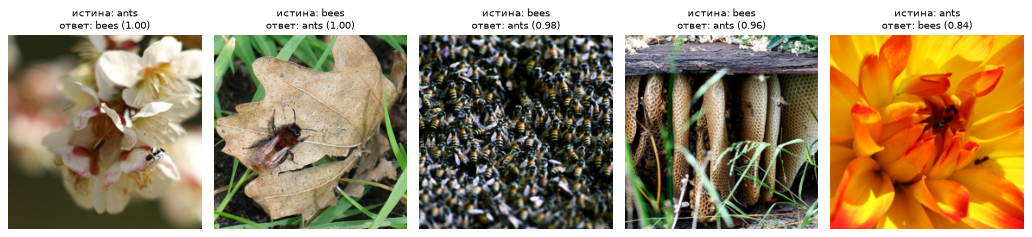

In [12]:
with torch.no_grad():
    prob_ft = torch.softmax(head_ft(E_va_ft), 1)
wrong = (pred_ft != yva).nonzero().ravel()
print(f"ошибок fine-tuned модели: {len(wrong)} из {len(yva)}; ошибок frozen-модели: {int((pred_frozen != yva).sum())}; общих: {int(((pred_frozen != yva) & (pred_ft != yva)).sum())}")
order = wrong[prob_ft[wrong].max(1).values.argsort(descending=True)][:6]
fig, ax = plt.subplots(1, max(len(order), 1), figsize=(2.6 * max(len(order), 1), 2.9))
for a_, i in zip(np.atleast_1d(ax), order):
    a_.imshow(show(Xva[i])); a_.axis("off")
    a_.set_title(f"истина: {CLASSES[yva[i]]}\nответ: {CLASSES[pred_ft[i]]} ({prob_ft[i].max():.2f})", fontsize=9)
plt.tight_layout(); plt.show()

### Чему нельзя верить без проверки

**1. Двумерная PCA-картинка.** У pretrained-признаков первые две компоненты содержат только 20 % дисперсии. Остальное — в десятках других направлений (90 % дисперсии набирается лишь на 72 компонентах), которых на картинке не видно. Точность «ближайшего центра» у frozen-модели в полном пространстве 0.961, в проекции — 0.935: часть информации о классах проекция теряет.

Ещё показательнее необученная сеть: у неё первые две компоненты содержат **89.7 %** дисперсии — проекция почти ничего не теряет, — а классы при этом не разделяются вовсе (accuracy 0.61). PCA выбирает оси по **разбросу**, а не по **разделимости классов**: направление, вдоль которого данные сильнее всего разбросаны (например, общая яркость или «зелёный фон / серый фон»), не обязано совпадать с направлением «муравей / пчела». Высокая доля объяснённой дисперсии говорит только о том, что данные почти плоские.

**2. Сырые косинусы.** На исходных embeddings косинус высок для любых пар: 0.667 для одного класса и 0.597 для разных — разница всего 0.07. У необученной сети — 0.989 и 0.989. Причина: после ReLU и усреднения все 512 компонент неотрицательны, все векторы лежат в одном «углу» пространства, и угол между любыми двумя мал. После центрирования картина осмысленная: +0.095 для одного класса и −0.086 для разных.

**3. Softmax-вероятности.** Среди ошибок выше есть ответы с высокой уверенностью. Вероятность на выходе softmax — не мера правоты.

## 6. Вывод

Цифры — из таблиц шага 11.

- **Ручные расчёты:** $\cos=8/9\approx0.889$; PCA для трёх точек на прямой — одна компонента $(1,1)/\sqrt2$ со всей дисперсией; энергия SVD 90.91 % и 99.09 %. Все три подтверждены кодом, включая равенство «собственные значения ковариации = $\sigma^2/N$».
- **Перенос работает.** Сравнение по трём показателям:

| Режим | Trainable params | Accuracy | Macro-F1 | Same/Diff cos (центр.) | Ближайший центр, 512-D |
|---|---|---|---|---|---|
| random backbone + head | 1 026 | 0.608 | 0.608 | +0.037 / −0.035 | 0.628 |
| frozen backbone + head | 1 026 | 0.961 | 0.961 | +0.095 / −0.086 | 0.961 |
| fine-tuned layer4 + head | 8 394 754 | 0.967 | 0.967 | +0.103 / −0.093 | 0.961 |

  Один и тот же head из 1026 параметров даёт 61 % на признаках необученной сети и 96 % на pretrained-признаках. Разница — целиком заслуга признаков, выученных на ImageNet.
- **Fine-tuning почти ничего не добавил.** Число обучаемых параметров выросло в 8 тысяч раз, accuracy — с 0.961 до 0.967: это **одна** картинка из 153 (ошибок 6 → 5, причём все 5 ошибок fine-tuned модели были и у frozen). Loss на train при этом упал до 0.0005 — модель запомнила обучающие картинки. По эпохам accuracy на val колеблется между 0.961 и 0.967, то есть различие лежит в пределах шума. Вывод: для этой задачи frozen backbone достаточно, а утверждать, что fine-tuning лучше, по этим данным нельзя.
- **Геометрия признаков.** Разность same/different косинусов на центрированных embeddings выросла с 0.181 до 0.196, доля дисперсии в PC1+PC2 — с 19.9 % до 20.8 %: дообучение слегка сдвинуло embeddings одного класса друг к другу, но feature space изменился мало — как и метрики.
- **PCA-график — не доказательство.** Вывод о разделимости сделан по трём независимым числам: macro-F1, разность косинусов, точность ближайшего центра в полном пространстве. 2D-проекция pretrained-признаков показывает 20 % дисперсии; проекция признаков необученной сети показывает 90 % дисперсии и никакого разделения.
- **Ограничения:** набор мал (153 картинки в val, одна картинка — 0.65 процентного пункта); шаг fine-tuning подбирался, хотя и по train; аугментация не использовалась; отдельного test-набора нет.

## 7. Вопросы на защиту

**1. Почему cosine similarity не зависит от общего масштаба векторов?**
$\cos(ax,y)=\dfrac{a\,x^Ty}{|a|\|x\|\|y\|}$ — при $a>0$ множитель сокращается. Косинус измеряет угол, то есть сравнивает направления. Для embeddings это отделяет «что на картинке» (направление) от «насколько сильно сработали признаки» (длина).

**2. Как PCA связано с eigenvectors covariance matrix и с SVD центрированной матрицы данных?**
Главные компоненты — собственные векторы $C=\frac1NX_c^TX_c$, дисперсии вдоль них — собственные значения. Подставим SVD $X_c=U\Sigma V^T$: $X_c^TX_c=V\Sigma U^TU\Sigma V^T=V\Sigma^2V^T$. Значит столбцы $V$ — собственные векторы $C$, а $\lambda_i=\sigma_i^2/N$. Через SVD считать устойчивее: не нужно формировать $X_c^TX_c$, что возвело бы число обусловленности в квадрат (лабораторная 9).

**3. Где извлекаются embeddings до classifier, и почему нельзя анализировать только softmax probabilities.**
В функции `embed`: `layer4(F3).mean(dim=(2, 3))` — выход последней свёрточной стадии, усреднённый по пространству (это и делает `avgpool` в ResNet), 512 чисел; слой `fc`/head к ним ещё не применён. Softmax-выход — это 2 числа с суммой 1, то есть по сути одно: почти вся информация о картинке уже потеряна. По нему нельзя увидеть структуру внутри класса, эффективную размерность или близость конкретных картинок. Кроме того, softmax насыщается: уверенно правильный и уверенно ошибочный ответ выглядят одинаково.